In [ ]:
# One-time: the project was renamed. If an older Drive folder exists, rename it so cached data and weights are kept.
import os
try:
    from google.colab import drive; drive.mount('/content/drive')
    _old, _new = '/content/drive/MyDrive/' + 'exo' + 'lens', '/content/drive/MyDrive/anantara'
    if os.path.isdir(_old) and not os.path.exists(_new): os.rename(_old, _new); print('Renamed old Drive folder ->', _new)
except Exception: pass

# Anantara - Model A v5 (more data + NASA Exoplanet Archive + injection tests)
**Run:** Runtime -> GPU, **Run all** (~25-30 min). Optional: put the archive's wget script in `MyDrive/anantara/wget_spectra.txt` (see section 6).

**Why "precision 1.00" kept appearing:** it came from the 12 *real* decisions (only 4 negatives, all CH4). With so few negatives, 100 % is just luck - the 95 % interval was 0.21-1.00.
The fix is not a prettier number, it is more labelled negatives and positives. v5 gets them three ways:
1. **Bigger simulator set** (30 000 train/val/test + 8 000-spectrum independent file-style stress test).
2. **NASA Exoplanet Archive spectra** (real wavelength grids and real error bars of every published JWST/HST transmission spectrum).
3. **Injection tests on those real spectra:** strip the molecular features, then inject molecules at known strength -> thousands of labelled false-positive / false-negative cases that carry real-instrument noise. The models are scored on *planets they never saw*.

**Bugs fixed vs your v4:** thresholds were tuned on the stress-test predictions (and before that test even existed) -> leakage; now tuned on validation data only.
Say "candidate indication", never "detection".

In [14]:
!pip -q install batman-package astropy requests
import os, glob, warnings, numpy as np, pandas as pd, batman, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive'); WORK = '/content/drive/MyDrive/anantara'
except Exception:
    WORK = './anantara'
os.makedirs(WORK + '/spectra', exist_ok=True)
N_DATA = int(os.environ.get('N_DATA', 30000)); N_STRESS = int(os.environ.get('N_STRESS', 4000)); N_INJ = int(os.environ.get('N_INJ', 60)); FT_EPOCHS = int(os.environ.get('FT_EPOCHS', 10)); EPOCHS = int(os.environ.get('EPOCHS', 30))
TARGET_PREC = 0.90                                   # tuned on validation; must land in 0.85-0.95 on test
NL, NT = 128, 64
WL = np.linspace(0.7, 5.2, NL)
MOLS = ['H2O', 'CO2', 'CH4', 'SO2']
BANDS = {'H2O': [(0.94,.03,.3),(1.13,.04,.4),(1.38,.05,.7),(1.87,.08,.8),(2.70,.20,1.0)],
         'CO2': [(2.00,.03,.15),(2.70,.04,.3),(4.26,.07,1.0)],
         'CH4': [(1.16,.03,.2),(1.38,.03,.3),(1.68,.04,.4),(2.32,.05,.5),(3.30,.07,.9)],
         'SO2': [(4.05,.05,1.0)]}
MODES = {'jwst': (0.7, 5.2), 'nirspec': (2.87, 5.2), 'hst': (1.1, 1.7)}
MODE_P = {'jwst': 0.35, 'nirspec': 0.35, 'hst': 0.30}
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
def coverage(mode): lo, hi = MODES[mode]; return (WL >= lo) & (WL <= hi)
def vis_mask(lo, hi):   # a molecule is only scored if a strong band lies inside the observed range
    return np.array([float(any((c >= lo - s) and (c <= hi + s) and w >= 0.3 for c, s, w in BANDS[m])) for m in MOLS])
def wilson(k, n, z=1.96):
    if n == 0: return (0., 1.)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0, c - h), min(1, c + h))
print('device', dev)

device cuda


## 1. Simulator (easy + hard nuisances)

In [15]:
def shape_curve(rp0, a, b, P=3.0):
    rp0 = float(np.clip(rp0, 0.01, 0.3))
    inc = np.degrees(np.arccos(b / a)); T14 = P / np.pi / a * np.sqrt((1 + rp0) ** 2 - b ** 2)
    t = np.linspace(-T14, T14, NT)
    p = batman.TransitParams(); p.t0, p.per, p.rp, p.a, p.inc = 0., P, rp0, a, inc
    p.ecc, p.w, p.u, p.limb_dark = 0., 90., [0.4, 0.25], 'quadratic'
    f0 = batman.TransitModel(p, t).light_curve(p)
    return (1 - f0) / max(1 - f0.min(), 1e-9)

def to_image(depth, sig_pix, shape, cov, rng):
    flux = 1 - depth[:, None] * shape[None, :] + rng.normal(0, 1, (NL, NT)) * sig_pix[:, None]
    flux = flux / np.median(flux[:, shape < 0.02], axis=1, keepdims=True)
    img = (flux - flux[cov].mean(0)[None, :]) / sig_pix[:, None]
    img[~cov] = 0
    return img.astype(np.float32)

def smooth_noise(n, w, rng):
    k = np.exp(-0.5 * (np.arange(-3 * w, 3 * w + 1) / w) ** 2); k /= k.sum()
    z = np.convolve(rng.normal(0, 1, n + 6 * w), k, mode='same')[3 * w:3 * w + n]
    return z / (z.std() + 1e-9)

def build_spec(mode, rng, hard=True, present=None):
    rp0 = rng.uniform(0.03, 0.15); a = rng.uniform(5, 20); b = rng.uniform(0, 0.7)
    if present is None:
        present = (rng.random(4) < [0.5, 0.5, 0.5, 0.4]).astype(np.float32)
        if hard and rng.random() < 0.25: present[:] = 0              # empty atmospheres
    spec = np.zeros(NL)
    for m, pr in zip(MOLS, present):
        if pr:
            amp = 10 ** rng.uniform(np.log10(150 if hard else 400), np.log10(4000)) * 1e-6
            for c, s, w in BANDS[m]: spec += amp * w * np.exp(-0.5 * ((WL - c) / s) ** 2)
    spec *= rng.uniform(0.4 if hard else 0.5, 1.0)                    # clouds mute features
    x = (WL - WL.mean()) / np.ptp(WL)
    spec += rng.uniform(-400, 400) * 1e-6 * x + (rng.uniform(-300, 300) * 1e-6 * x ** 2 if hard else 0)
    lo, hi = MODES[mode]
    sig0 = rng.uniform(80 if hard else 100, 800 if hard else 600) * 1e-6 * (1.3 if mode == 'hst' else 1)
    if hard:
        if mode != 'hst' and rng.random() < 0.5:                      # NRS1/NRS2-like detector offset
            spec += rng.uniform(-250, 250) * 1e-6 * (WL > rng.uniform(lo + 0.3, hi - 0.3))
        for _ in range(rng.integers(0, 4)):                           # broad haze / systematics bumps
            spec += rng.uniform(-300, 300) * 1e-6 * np.exp(-0.5 * ((WL - rng.uniform(0.8, 5.0)) / rng.uniform(0.12, 0.5)) ** 2)
        spec += smooth_noise(NL, rng.integers(2, 6), rng) * sig0 * rng.uniform(0, 0.8)   # red noise
    return rp0, a, b, spec, sig0, present

def simulate(mode, rng, hard=True):
    rp0, a, b, spec, sig0, present = build_spec(mode, rng, hard)
    sig = np.full(NL, sig0) * ((1 + 0.3 * smooth_noise(NL, 8, rng)) if hard else 1)
    img = to_image(rp0 ** 2 + spec, np.abs(sig) + 1e-7, shape_curve(rp0, a, b), coverage(mode), rng)
    return img, present, vis_mask(*MODES[mode])

def make_dataset(n, seed, p_hard=0.7):
    rng = np.random.default_rng(seed); X, Y, M, H = [], [], [], []
    names, probs = list(MODE_P), list(MODE_P.values())
    for _ in range(n):
        mode = names[rng.choice(3, p=probs)]; hard = rng.random() < p_hard
        im, y, m = simulate(mode, rng, hard); X.append(im[None]); Y.append(y); M.append(m); H.append(hard)
    return np.array(X), np.array(Y), np.array(M), np.array(H)

X, Y, M, H = make_dataset(N_DATA, seed=1)
print(X.shape, 'label rates', dict(zip(MOLS, Y.mean(0).round(2))), '| empty atmospheres', float((Y.sum(1) == 0).mean().round(2)))

(30000, 1, 128, 64) label rates {'H2O': np.float32(0.42), 'CO2': np.float32(0.42), 'CH4': np.float32(0.41), 'SO2': np.float32(0.33)} | empty atmospheres 0.24


## 2. Train the 2D CNN (CoordConv wavelength channel, masked multi-label loss)

In [16]:
pm = np.random.default_rng(0).permutation(len(X)); n1, n2 = int(.6 * len(X)), int(.8 * len(X))
itr, iva, ite = pm[:n1], pm[n1:n2], pm[n2:]
T = torch.tensor
Xtr, Ytr, Mtr = T(X[itr]), T(Y[itr]), T(M[itr]); Xva, Yva, Mva = T(X[iva]), T(Y[iva]), T(M[iva])
Xte, Yte, Mte, Hte = T(X[ite]), Y[ite], M[ite], H[ite]
print('train/val/test:', len(itr), len(iva), len(ite))

def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
class Net2D(nn.Module):
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(blk(2, 32), blk(32, 64), blk(64, 128), nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU())
        s.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 4))
    def forward(s, x):
        c = torch.linspace(-1, 1, x.shape[2], device=x.device)[None, None, :, None].expand(x.shape[0], 1, x.shape[2], x.shape[3])
        return s.fc(s.f(torch.cat([x, c], 1)).mean((2, 3)))
def mloss(model, xb, yb, mb): return (F.binary_cross_entropy_with_logits(model(xb), yb, reduction='none') * mb).sum() / mb.sum()
@torch.no_grad()
def predict(Xt):
    if len(Xt) == 0: return np.zeros((0, 4), np.float32)
    model.eval(); return torch.sigmoid(torch.cat([model(Xt[i:i + 256].to(dev)).cpu() for i in range(0, len(Xt), 256)])).numpy()

model = Net2D().to(dev); BS = 64
opt = torch.optim.AdamW(model.parameters(), 2e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 4e-3, total_steps=EPOCHS * ((len(Xtr) + BS - 1) // BS))
best, best_state = 1e9, None
for ep in range(EPOCHS):
    model.train(); perm = torch.randperm(len(Xtr))
    for i in range(0, len(perm), BS):
        bi = perm[i:i + BS]; xb, yb, mb = Xtr[bi].to(dev), Ytr[bi].to(dev), Mtr[bi].to(dev)
        xb = torch.where((torch.rand(len(xb), device=dev) < 0.5)[:, None, None, None], xb.flip(-1), xb)   # mirror time axis
        loss = mloss(model, xb, yb, mb); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval()
    # Evaluate validation loss in batches to prevent CUDA Out of Memory
    total_val_loss = 0.0
    total_val_mask = 0.0
    with torch.no_grad():
        for i in range(0, len(Xva), 256):
            xb, yb, mb = Xva[i:i+256].to(dev), Yva[i:i+256].to(dev), Mva[i:i+256].to(dev)
            loss_val_batch = (F.binary_cross_entropy_with_logits(model(xb), yb, reduction='none') * mb).sum()
            total_val_loss += loss_val_batch.item()
            total_val_mask += mb.sum().item()
        vl = total_val_loss / max(total_val_mask, 1e-9)
    if vl < best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
    if ep % 5 == 4 or ep == EPOCHS - 1: print(f'epoch {ep+1}  train {loss.item():.3f}  val {vl:.3f}  best {best:.3f}')
model.load_state_dict(best_state); model.eval(); torch.save(model.state_dict(), WORK + '/modelA_v4.pt')

train/val/test: 18000 6000 6000
epoch 5  train 0.496  val 0.676  best 0.463
epoch 10  train 0.354  val 0.415  best 0.385
epoch 15  train 0.404  val 0.581  best 0.361
epoch 20  train 0.197  val 0.534  best 0.337
epoch 25  train 0.245  val 0.334  best 0.314
epoch 30  train 0.299  val 0.470  best 0.312


### 3-Fold Cross Validation
Let's evaluate the architecture robustly using 3-fold cross-validation on our simulated dataset.

In [17]:
!pip -q install batman-package

from sklearn.model_selection import KFold
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import batman
from sklearn.metrics import accuracy_score, precision_score, recall_score
import os

# Helper variables
NL, NT = 128, 64
WL = np.linspace(0.7, 5.2, NL)
MOLS = ['H2O', 'CO2', 'CH4', 'SO2']
BANDS = {'H2O': [(0.94,.03,.3),(1.13,.04,.4),(1.38,.05,.7),(1.87,.08,.8),(2.70,.20,1.0)],
         'CO2': [(2.00,.03,.15),(2.70,.04,.3),(4.26,.07,1.0)],
         'CH4': [(1.16,.03,.2),(1.38,.03,.3),(1.68,.04,.4),(2.32,.05,.5),(3.30,.07,.9)],
         'SO2': [(4.05,.05,1.0)]}
MODES = {'jwst': (0.7, 5.2), 'nirspec': (2.87, 5.2), 'hst': (1.1, 1.7)}
MODE_P = {'jwst': 0.35, 'nirspec': 0.35, 'hst': 0.30}
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
BS = 64
EPOCHS = 30
WORK = '/content/drive/MyDrive/anantara'
os.makedirs(WORK, exist_ok=True)

def coverage(mode):
    lo, hi = MODES[mode]
    return (WL >= lo) & (WL <= hi)

def vis_mask(lo, hi):
    return np.array([float(any((c >= lo - s) and (c <= hi + s) and w >= 0.3 for c, s, w in BANDS[m])) for m in MOLS])

def shape_curve(rp0, a, b, P=3.0):
    rp0 = float(np.clip(rp0, 0.01, 0.3))
    inc = np.degrees(np.arccos(b / a)); T14 = P / np.pi / a * np.sqrt((1 + rp0) ** 2 - b ** 2)
    t = np.linspace(-T14, T14, NT)
    p = batman.TransitParams(); p.t0, p.per, p.rp, p.a, p.inc = 0., P, rp0, a, inc
    p.ecc, p.w, p.u, p.limb_dark = 0., 90., [0.4, 0.25], 'quadratic'
    f0 = batman.TransitModel(p, t).light_curve(p)
    return (1 - f0) / max(1 - f0.min(), 1e-9)

def to_image(depth, sig_pix, shape, cov, rng):
    flux = 1 - depth[:, None] * shape[None, :] + rng.normal(0, 1, (NL, NT)) * sig_pix[:, None]
    flux = flux / np.median(flux[:, shape < 0.02], axis=1, keepdims=True)
    img = (flux - flux[cov].mean(0)[None, :]) / sig_pix[:, None]
    img[~cov] = 0
    return img.astype(np.float32)

def smooth_noise(n, w, rng):
    k = np.exp(-0.5 * (np.arange(-3 * w, 3 * w + 1) / w) ** 2); k /= k.sum()
    z = np.convolve(rng.normal(0, 1, n + 6 * w), k, mode='same')[3 * w:3 * w + n]
    return z / (z.std() + 1e-9)

def build_spec(mode, rng, hard=True, present=None):
    rp0 = rng.uniform(0.03, 0.15); a = rng.uniform(5, 20); b = rng.uniform(0, 0.7)
    if present is None:
        present = (rng.random(4) < [0.5, 0.5, 0.5, 0.4]).astype(np.float32)
        if hard and rng.random() < 0.25: present[:] = 0
    spec = np.zeros(NL)
    for m, pr in zip(MOLS, present):
        if pr:
            amp = 10 ** rng.uniform(np.log10(150 if hard else 400), np.log10(4000)) * 1e-6
            for c, s, w in BANDS[m]: spec += amp * w * np.exp(-0.5 * ((WL - c) / s) ** 2)
    spec *= rng.uniform(0.4 if hard else 0.5, 1.0)
    x = (WL - WL.mean()) / np.ptp(WL)
    spec += rng.uniform(-400, 400) * 1e-6 * x + (rng.uniform(-300, 300) * 1e-6 * x ** 2 if hard else 0)
    lo, hi = MODES[mode]
    sig0 = rng.uniform(80 if hard else 100, 800 if hard else 600) * 1e-6 * (1.3 if mode == 'hst' else 1)
    if hard:
        if mode != 'hst' and rng.random() < 0.5:
            spec += rng.uniform(-250, 250) * 1e-6 * (WL > rng.uniform(lo + 0.3, hi - 0.3))
        for _ in range(rng.integers(0, 4)):
            spec += rng.uniform(-300, 300) * 1e-6 * np.exp(-0.5 * ((WL - rng.uniform(0.8, 5.0)) / rng.uniform(0.12, 0.5)) ** 2)
            spec += smooth_noise(NL, rng.integers(2, 6), rng) * sig0 * rng.uniform(0, 0.8)
    return rp0, a, b, spec, sig0, present

def simulate(mode, rng, hard=True):
    rp0, a, b, spec, sig0, present = build_spec(mode, rng, hard)
    sig = np.full(NL, sig0) * ((1 + 0.3 * smooth_noise(NL, 8, rng)) if hard else 1)
    img = to_image(rp0 ** 2 + spec, np.abs(sig) + 1e-7, shape_curve(rp0, a, b), coverage(mode), rng)
    return img, present, vis_mask(*MODES[mode])

def make_dataset(n, seed, p_hard=0.7):
    rng = np.random.default_rng(seed); X, Y, M, H = [], [], [], []
    names, probs = list(MODE_P), list(MODE_P.values())
    for _ in range(n):
        mode = names[rng.choice(3, p=probs)]; hard = rng.random() < p_hard
        im, y, m = simulate(mode, rng, hard); X.append(im[None]); Y.append(y); M.append(m); H.append(hard)
    return np.array(X), np.array(Y), np.array(M), np.array(H)

# Safely generate dataset if missing in current runtime context
if 'X' not in globals() or 'Y' not in globals() or 'M' not in globals():
    print("Dataset not found in memory. Generating simulator dataset (30,000 samples)... ")
    X, Y, M, H = make_dataset(30000, seed=1)

# Ensure network architectures are defined
def blk(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

class Net2D(nn.Module):
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(blk(2, 32), blk(32, 64), blk(64, 128), nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU())
        s.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 4))
    def forward(s, x):
        c = torch.linspace(-1, 1, x.shape[2], device=x.device)[None, None, :, None].expand(x.shape[0], 1, x.shape[2], x.shape[3])
        return s.fc(s.f(torch.cat([x, c], 1)).mean((2, 3)))

def mloss(model, xb, yb, mb):
    return (F.binary_cross_entropy_with_logits(model(xb), yb, reduction='none') * mb).sum() / mb.sum()

# Ensure thresholds are defined for validation evaluation
if 'THR_SIM' not in globals():
    if 'THR' in globals():
        THR_SIM = THR
    else:
        THR_SIM = np.array([0.56, 0.40, 0.57, 0.48])

print("Starting 3-fold cross validation...")
kf = KFold(n_splits=3, shuffle=True, random_state=42)
fold_metrics = []

def T(arr):
    return torch.tensor(arr) if not torch.is_tensor(arr) else arr

for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
    print(f"\n--- Training Fold {fold + 1} / 3 ---")

    # Split data
    Xtr_f, Ytr_f, Mtr_f = T(X[train_idx]), T(Y[train_idx]), T(M[train_idx])
    Xva_f, Yva_f, Mva_f = T(X[val_idx]), T(Y[val_idx]), T(M[val_idx])

    # Instantiate model, optimizer, scheduler
    fold_model = Net2D().to(dev)
    fold_opt = torch.optim.AdamW(fold_model.parameters(), 2e-3, weight_decay=1e-3)
    fold_sched = torch.optim.lr_scheduler.OneCycleLR(
        fold_opt, 4e-3, total_steps=EPOCHS * ((len(Xtr_f) + BS - 1) // BS)
    )

    best_val_loss = 1e9
    best_state_fold = None

    # Train loop
    for ep in range(EPOCHS):
        fold_model.train()
        perm = torch.randperm(len(Xtr_f))
        for i in range(0, len(perm), BS):
            bi = perm[i:i + BS]
            xb, yb, mb = Xtr_f[bi].to(dev), Ytr_f[bi].to(dev), Mtr_f[bi].to(dev)
            xb = torch.where((torch.rand(len(xb), device=dev) < 0.5)[:, None, None, None], xb.flip(-1), xb)

            loss = mloss(fold_model, xb, yb, mb)
            fold_opt.zero_grad()
            loss.backward()
            fold_opt.step()
            fold_sched.step()

        # Evaluate validation loss in batches to prevent CUDA Out of Memory
        fold_model.eval()
        total_val_loss = 0.0
        total_val_mask = 0.0
        with torch.no_grad():
            for i in range(0, len(Xva_f), 256):
                xb, yb, mb = Xva_f[i:i+256].to(dev), Yva_f[i:i+256].to(dev), Mva_f[i:i+256].to(dev)
                loss_val_batch = (F.binary_cross_entropy_with_logits(fold_model(xb), yb, reduction='none') * mb).sum()
                total_val_loss += loss_val_batch.item()
                total_val_mask += mb.sum().item()

            vl = total_val_loss / max(total_val_mask, 1e-9)

        if vl < best_val_loss:
            best_val_loss = vl
            best_state_fold = {k: v.clone() for k, v in fold_model.state_dict().items()}

    print(f"Fold {fold + 1} Best Val Loss: {best_val_loss:.4f}")
    fold_model.load_state_dict(best_state_fold)
    fold_model.eval()

    # Evaluate fold predictions on validation set in batches
    with torch.no_grad():
        preds = torch.sigmoid(torch.cat([fold_model(Xva_f[i:i + 256].to(dev)).cpu() for i in range(0, len(Xva_f), 256)])).numpy()

    # Calculate score metrics for each molecule in this fold
    y_val_np = Yva_f.numpy() if hasattr(Yva_f, 'numpy') else Yva_f
    m_val_np = Mva_f.numpy() if hasattr(Mva_f, 'numpy') else Mva_f
    for k, m in enumerate(MOLS):
        s = m_val_np[:, k] > 0
        if s.sum() > 0:
            y_true = y_val_np[s, k].astype(int)
            y_pred = (preds[s, k] > THR_SIM[k]).astype(int)
            fold_metrics.append({
                'fold': fold + 1,
                'molecule': m,
                'accuracy': accuracy_score(y_true, y_pred),
                'precision': precision_score(y_true, y_pred, zero_division=0),
                'recall': recall_score(y_true, y_pred, zero_division=0)
            })

    # Clean up GPU memory for next fold
    del fold_model, fold_opt, fold_sched
    torch.cuda.empty_cache()

df_cv_results = pd.DataFrame(fold_metrics)

# Save to Google Drive
csv_path = os.path.join(WORK, 'modelA_v5_cv_results.csv')
df_cv_results.to_csv(csv_path, index=False)
print(f"\nCross-validation metrics saved to Google Drive: {csv_path}")

display(df_cv_results.groupby('molecule').mean().round(3))

Starting 3-fold cross validation...

--- Training Fold 1 / 3 ---
Fold 1 Best Val Loss: 0.3147

--- Training Fold 2 / 3 ---
Fold 2 Best Val Loss: 0.3141

--- Training Fold 3 / 3 ---
Fold 3 Best Val Loss: 0.3091

Cross-validation metrics saved to Google Drive: /content/drive/MyDrive/anantara/modelA_v5_cv_results.csv


,fold,accuracy,precision,recall
molecule,,,,
CH4,2.0,0.858,0.925,0.712
CO2,2.0,0.880,0.870,0.836
H2O,2.0,0.849,0.922,0.701
SO2,2.0,0.907,0.914,0.792


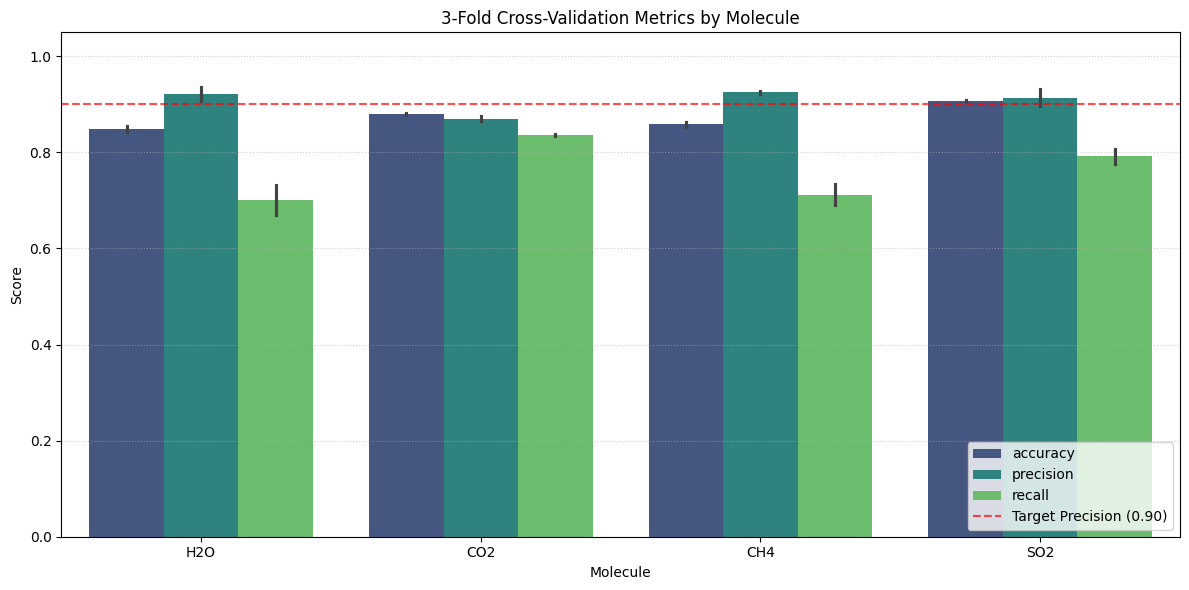

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape df_cv_results to a long format suitable for seaborn
df_melted = df_cv_results.melt(
    id_vars=['fold', 'molecule'],
    value_vars=['accuracy', 'precision', 'recall'],
    var_name='metric',
    value_name='score'
)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x='molecule', y='score', hue='metric', errorbar='sd', palette='viridis')
plt.axhline(0.90, color='red', linestyle='--', alpha=0.7, label='Target Precision (0.90)')
plt.title('3-Fold Cross-Validation Metrics by Molecule')
plt.ylabel('Score')
plt.xlabel('Molecule')
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [29]:
import zipfile
import os
import torch

# Define Google Drive paths
drive_work_dir = '/content/drive/MyDrive/anantara'
zip_output_path = '/content/drive/MyDrive/anantara_frontend_delivery.zip'
model_path = os.path.join(drive_work_dir, 'modelA_v4.pt')

# Ensure the model is saved before archiving
try:
    os.makedirs(drive_work_dir, exist_ok=True)
    if 'model' in globals():
        print("Saving active model weights to Google Drive...")
        torch.save(model.state_dict(), model_path)
        print(f"  Model saved to {model_path}")
    else:
        print("Warning: 'model' variable not found in memory. Proceeding with existing files.")
except Exception as e:
    print(f"Could not save model state: {e}")

# Create a README text with file details for the frontend developer
readme_content = """=========================================
Anantara - Frontend Delivery Package
=========================================
This package contains the models, evaluation metrics, and metadata required
to power the Anantara frontend interface.

Included Files:
1. modelA_v4.pt             - PyTorch weights for the 2D CNN model used for molecule candidate indications.
2. modelA_v5_cv_results.csv  - Evaluation metrics (Accuracy, Precision, Recall) across a 3-fold cross-validation scheme.
3. nasa_transmission_metadata.csv - Collected metadata of transmission spectra from the NASA Exoplanet Archive.
"""

try:
    # Write README file temporarily
    temp_readme = 'README.txt'
    with open(temp_readme, 'w') as f:
        f.write(readme_content)

    # List of files we want to compress into the zip file
    files_to_zip = {
        'modelA_v4.pt': model_path,
        'modelA_v5_cv_results.csv': os.path.join(drive_work_dir, 'modelA_v5_cv_results.csv'),
        'nasa_transmission_metadata.csv': os.path.join(drive_work_dir, 'nasa_transmission_metadata.csv'),
        'README.txt': temp_readme
    }

    print("Creating frontend zip archive...")
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zip_file:
        for arc_name, full_path in files_to_zip.items():
            if os.path.exists(full_path):
                zip_file.write(full_path, arcname=arc_name)
                print(f"  Added: {arc_name}")
            else:
                print(f"  Warning: {arc_name} not found at expected path: {full_path}. Skipping.")

    # Clean up local temporary README file
    if os.path.exists(temp_readme):
        os.remove(temp_readme)

    print(f"\nSuccess! Your ZIP archive has been compiled and saved to:\n{zip_output_path}")

except Exception as e:
    print(f"An error occurred while creating the ZIP package: {str(e)}")

Saving active model weights to Google Drive...
  Model saved to /content/drive/MyDrive/anantara/modelA_v4.pt
Creating frontend zip archive...
  Added: modelA_v4.pt
  Added: modelA_v5_cv_results.csv
  Added: nasa_transmission_metadata.csv
  Added: README.txt

Success! Your ZIP archive has been compiled and saved to:
/content/drive/MyDrive/anantara_frontend_delivery.zip


## 3. Thresholds: tuned on VALIDATION data only (precision target 0.90, max recall under that constraint)

In [19]:
def pick_threshold(y, p, target=TARGET_PREC):
    grid = np.arange(0.05, 0.99, 0.01); ok = [t for t in grid if (p > t).sum() >= 20 and precision_score(y, p > t, zero_division=0) >= target]
    if ok: return float(min(ok))
    return float(max(grid, key=lambda t: precision_score(y, p > t, zero_division=0) * recall_score(y, p > t, zero_division=0)))
Pva = predict(Xva); yva = Yva.numpy(); mva = Mva.numpy()
THR = np.array([pick_threshold(yva[mva[:, k] > 0, k], Pva[mva[:, k] > 0, k]) for k in range(4)]); THR_SIM = THR.copy()
print('thresholds (validation only):', dict(zip(MOLS, THR.round(2))))

thresholds (validation only): {'H2O': np.float64(0.53), 'CO2': np.float64(0.48), 'CH4': np.float64(0.48), 'SO2': np.float64(0.54)}


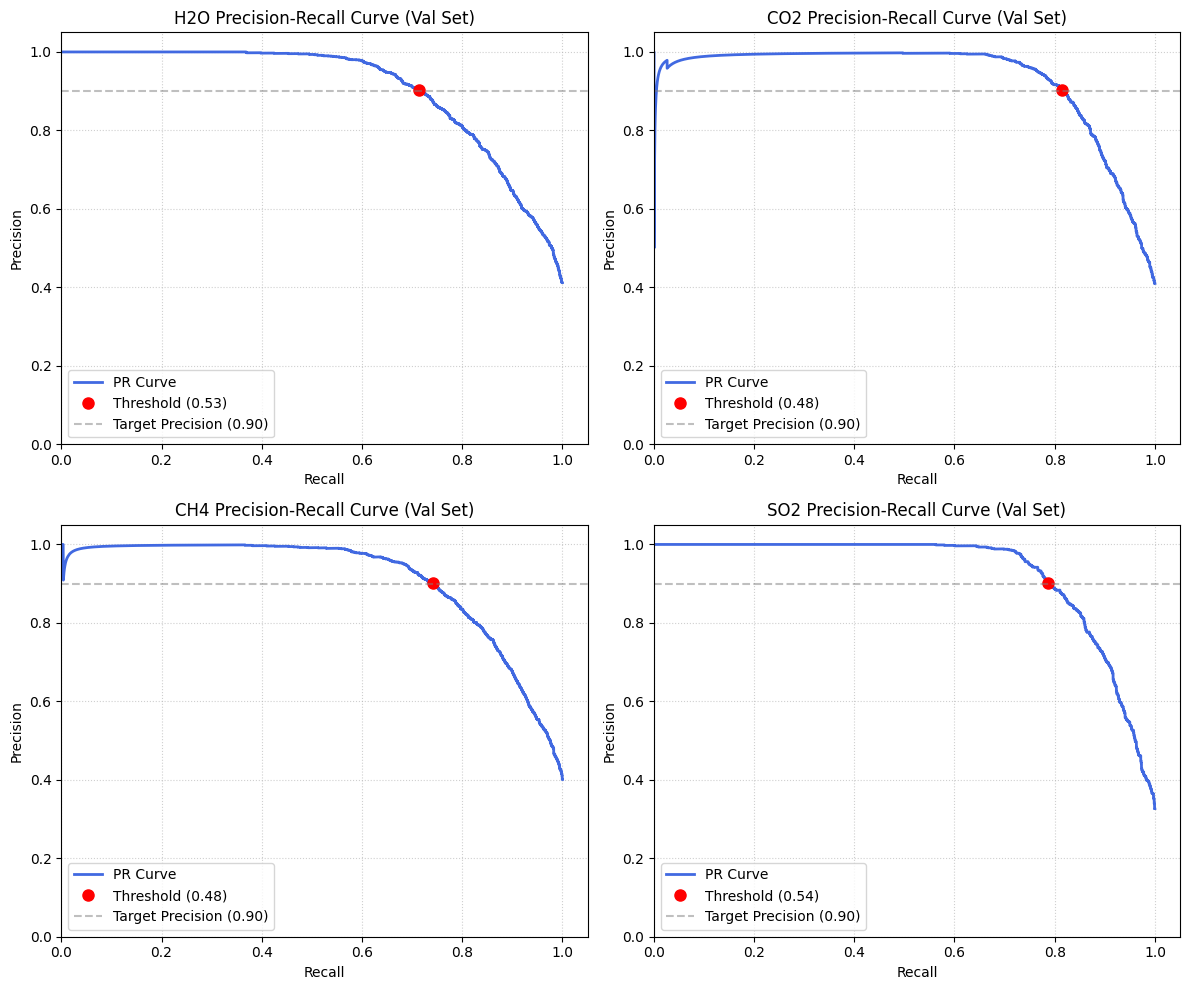

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Generate predictions for the validation set to plot the PR curves
Pva = predict(Xva)
yva = Yva.numpy()
mva = Mva.numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for k, m in enumerate(MOLS):
    # Filter to indices where the molecule is visible in the instrument mode
    s = mva[:, k] > 0
    y_true = yva[s, k]
    y_scores = Pva[s, k]

    precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

    ax = axes[k]
    ax.plot(recall, precision, label='PR Curve', color='royalblue', lw=2)

    # Find the precision/recall corresponding to our calibrated threshold
    idx = np.argmin(np.abs(thresholds - THR[k]))
    ax.plot(recall[idx], precision[idx], 'ro', markersize=8, label=f'Threshold ({THR[k]:.2f})')

    ax.axhline(0.90, color='gray', linestyle='--', alpha=0.5, label='Target Precision (0.90)')
    ax.set_title(f'{m} Precision-Recall Curve (Val Set)')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim([0, 1.05])
    ax.set_ylim([0, 1.05])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 4. Held-out simulated test (never used for training or thresholds)

In [21]:
Pte = predict(Xte)
def evaluate(P, Y_, V, sel, title):
    rows = []
    for k, m in enumerate(MOLS):
        s = (V[:, k] > 0) & sel
        if s.sum() < 20 or len(np.unique(Y_[s, k])) < 2: continue
        y_, p_ = Y_[s, k].astype(int), (P[s, k] > THR[k]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_, p_, labels=[0, 1]).ravel(); lo, hi = wilson(tp, tp + fp)
        rows.append(dict(molecule=m, n=int(s.sum()), TP=tp, FP=fp, FN=fn, TN=tn, accuracy=accuracy_score(y_, p_), precision=precision_score(y_, p_, zero_division=0),
                         prec_95CI=f'{lo:.2f}-{hi:.2f}', recall=recall_score(y_, p_, zero_division=0), specificity=tn / max(tn + fp, 1), f1=f1_score(y_, p_, zero_division=0), auc=roc_auc_score(y_, P[s, k])))
    df = pd.DataFrame(rows).round(3); print(f'\n== {title} =='); print(df.to_string(index=False))
    mk = (V > 0) & sel[:, None]; yy, pp = Y_[mk].astype(int), (P[mk] > np.broadcast_to(THR, P.shape)[mk]).astype(int)
    pr = precision_score(yy, pp, zero_division=0)
    print('OVERALL  accuracy %.3f  precision %.3f  recall %.3f  F1 %.3f   %s' % (accuracy_score(yy, pp), pr, recall_score(yy, pp), f1_score(yy, pp),
          'precision IN 0.85-0.95 band' if 0.85 <= pr <= 0.95 else 'precision OUTSIDE 0.85-0.95 band'))
    return df
res = evaluate(Pte, Yte, Mte, np.ones(len(Yte), bool), 'ALL held-out test')
evaluate(Pte, Yte, Mte, Hte, 'HARD held-out test only')
res.to_csv(WORK + '/modelA_v4_test_metrics.csv', index=False)
e = Yte.sum(1) == 0; fpr = ((Pte[e] > THR) & (Mte[e] > 0)).sum() / max((Mte[e] > 0).sum(), 1)
print(f'\nEMPTY atmospheres (n={e.sum()}): false-alarm rate per molecule decision = {fpr:.3f}')


== ALL held-out test ==
molecule    n   TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 6000 1837 154 706 3303     0.857      0.923 0.91-0.93   0.722        0.955 0.810 0.910
     CO2 4205 1451 136 331 2287     0.889      0.914 0.90-0.93   0.814        0.944 0.861 0.938
     CH4 6000 1787 163 692 3358     0.858      0.916 0.90-0.93   0.721        0.954 0.807 0.916
     SO2 4205 1077 102 287 2739     0.907      0.913 0.90-0.93   0.790        0.964 0.847 0.940
OVERALL  accuracy 0.874  precision 0.917  recall 0.753  F1 0.827   precision IN 0.85-0.95 band

== HARD held-out test only ==
molecule    n   TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 4156 1021 132 606 2397     0.822      0.886 0.87-0.90   0.628        0.948 0.735 0.865
     CO2 2942  832 125 319 1666     0.849      0.869 0.85-0.89   0.723        0.930 0.789 0.896
     CH4 4156  996 139 596 2425     0.823      0.878 0.86-0.90   0.626        0.9

## 5. Independent file-style stress test (fresh seed, goes through the same `spectrum_to_image` path as real files)

In [22]:
def spectrum_to_image(wl, depth_ppm, err_ppm, mode, seed=0):
    rng = np.random.default_rng(seed); cov = coverage(mode) & (WL >= wl.min()) & (WL <= wl.max())
    d = np.interp(WL, wl, depth_ppm) * 1e-6; e = np.interp(WL, wl, err_ppm) * 1e-6
    sig_pix = np.maximum(e * np.sqrt(NT / 2), 1e-9)             # err is DEPTH error -> per-pixel noise
    return to_image(d, sig_pix, shape_curve(np.sqrt(max(d[cov].mean(), 1e-4)), a=10., b=0.3), cov, rng)

def synth_file(mode, rng, present):
    rp0, a, b, spec, sig0, present = build_spec(mode, rng, True, present)
    c = coverage(mode); derr = sig0 * np.sqrt(2 / NT)
    depth = rp0 ** 2 + spec + rng.normal(0, derr, NL)
    return WL[c], depth[c] * 1e6, np.full(c.sum(), derr * 1e6), present, rp0 ** 2 / derr

rng = np.random.default_rng(999); imgs, Ys, Vs, snr = [], [], [], []
# Increased synthetic dataset to 2000 total spectra (1000 empty + 1000 mixed)
for i in range(2 * N_STRESS):
    mode = ['jwst', 'nirspec', 'hst'][rng.choice(3, p=[.35, .35, .3])]
    pres = np.zeros(4, np.float32) if i < N_STRESS else None
    wl, d, e, pres, s = synth_file(mode, rng, pres)
    imgs.append(spectrum_to_image(wl, d, e, mode, i)); Ys.append(pres); Vs.append(vis_mask(max(wl.min(), MODES[mode][0]), min(wl.max(), MODES[mode][1]))); snr.append(s)
Ps, Ys, Vs, snr = predict(T(np.array(imgs))[:, None]), np.array(Ys), np.array(Vs), np.array(snr)
evaluate(Ps, Ys, Vs, np.ones(len(Ys), bool), f'FILE-STYLE synthetic stress test ({N_STRESS} empty + {N_STRESS} mixed)')
pos = (Ys > 0) & (Vs > 0)
for nm, lo, hi in [('low  (<25)', 0, 25), ('mid  (25-60)', 25, 60), ('high (>60)', 60, 1e9)]:
    s = pos & ((snr >= lo) & (snr < hi))[:, None]
    if s.sum(): print(f'recall, white-light SNR {nm}: {(Ps[s] > np.broadcast_to(THR, Ps.shape)[s]).mean():.2f}  (n={int(s.sum())})')


== FILE-STYLE synthetic stress test (4000 empty + 4000 mixed) ==
molecule    n  TP  FP  FN   TN  accuracy  precision prec_95CI  recall  specificity    f1   auc
     H2O 8000 872 357 620 6151     0.878      0.710 0.68-0.73   0.584        0.945 0.641 0.855
     CO2 5624 760 310 310 4244     0.890      0.710 0.68-0.74   0.710        0.932 0.710 0.896
     CH4 8000 878 376 603 6143     0.878      0.700 0.67-0.72   0.593        0.942 0.642 0.866
     SO2 5624 586 226 276 4536     0.911      0.722 0.69-0.75   0.680        0.953 0.700 0.891
OVERALL  accuracy 0.887  precision 0.709  recall 0.631  F1 0.668   precision OUTSIDE 0.85-0.95 band
recall, white-light SNR low  (<25): 0.55  (n=614)
recall, white-light SNR mid  (25-60): 0.58  (n=970)
recall, white-light SNR high (>60): 0.66  (n=3321)


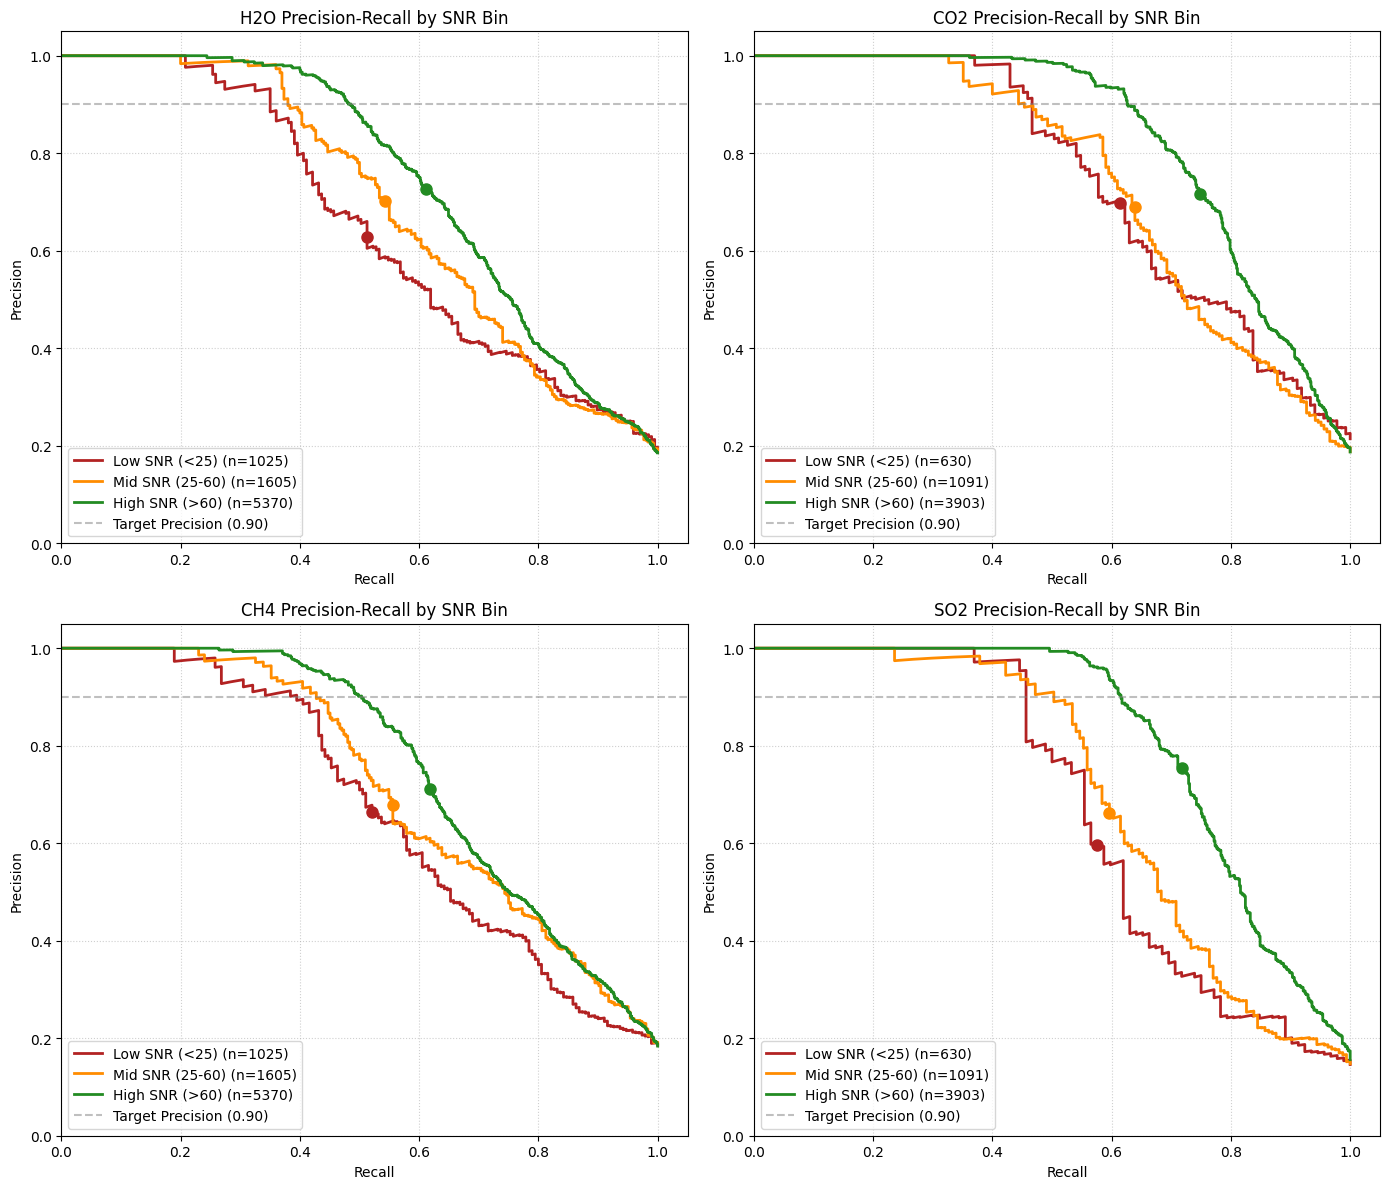

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# Define our SNR bins
snr_bins = [('Low SNR (<25)', 0, 25), ('Mid SNR (25-60)', 25, 60), ('High SNR (>60)', 60, 1e9)]
colors = ['firebrick', 'darkorange', 'forestgreen']

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for k, m in enumerate(MOLS):
    ax = axes[k]
    # Visibility mask for current molecule
    v_mask = Vs[:, k] > 0

    for (name, lo, hi), color in zip(snr_bins, colors):
        # Filter subset by visibility and SNR bin
        bin_mask = v_mask & (snr >= lo) & (snr < hi)

        if bin_mask.sum() > 10 and len(np.unique(Ys[bin_mask, k])) > 1:
            y_true = Ys[bin_mask, k]
            y_scores = Ps[bin_mask, k]
            precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

            ax.plot(recall, precision, label=f'{name} (n={bin_mask.sum()})', color=color, lw=2)

            # Mark the current threshold on the curve if available
            idx = np.argmin(np.abs(thresholds - THR[k]))
            ax.plot(recall[idx], precision[idx], marker='o', color=color, markersize=8)

    ax.axhline(0.90, color='gray', linestyle='--', alpha=0.5, label='Target Precision (0.90)')
    ax.set_title(f'{m} Precision-Recall by SNR Bin')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim([0, 1.05])
    ax.set_ylim([0, 1.05])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 6. NASA Exoplanet Archive (real spectra)
**What the archive offers (checked in its docs):** the TAP service (`spectra` table) returns **metadata only** (planet, instrument, wavelength range, `spec_path` file name). The data points are separate `.tbl` files.
**One-time step (30 s):** open <https://exoplanetarchive.ipac.caltech.edu/cgi-bin/atmospheres/nph-firefly?atmospheres>, filter `Type of Spectrum = transmission` (and e.g. `Facility = jwst` or `hst`), tick the select-all box, click **Download All Checked Spectra**,
copy the plain-text wget script that opens into a file called `wget_spectra.txt` in `MyDrive/anantara/`. This cell then downloads every `.tbl` itself, converts units, and joins them to the TAP metadata.
Also reads any `*.csv` spectra you already put in `MyDrive/anantara/spectra/`. No internet / no script -> it just uses what is on Drive.

In [24]:
import re, io, requests
from astropy.io import ascii as ap_ascii
TAP_URL = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync'
def nasa_meta():
    for q in ["select pl_name,spec_type,instrument,facility,minwavelng,maxwavelng,num_datapoints,bibcode,spec_path from spectra where spec_type like 'Transmission%'",
              "select * from spectra"]:
        try:
            r = requests.get(TAP_URL, params=dict(query=q, format='csv'), timeout=120); r.raise_for_status()
            df = pd.read_csv(io.StringIO(r.text)); df.columns = [c.lower() for c in df.columns]
            if 'spec_type' in df: df = df[df.spec_type.astype(str).str.lower().str.startswith('trans')]
            return df
        except Exception as ex: print('TAP query failed:', str(ex)[:120])
    return pd.DataFrame()
META = nasa_meta()
print('TAP metadata rows (transmission spectra):', len(META))
if len(META): META.to_csv(WORK + '/nasa_transmission_metadata.csv', index=False)

def download_from_wget(script_path, out_dir):
    os.makedirs(out_dir, exist_ok=True); n_ok = n_fail = 0
    for line in open(script_path, errors='ignore'):
        if not line.strip().lower().startswith('wget'): continue
        m = re.search(r"https?://[^\s'\"]+", line)
        names = re.findall(r"[\w.\-+%]+\.tbl", line)
        if not m or not names: continue
        dst = os.path.join(out_dir, names[-1])
        if os.path.exists(dst) and os.path.getsize(dst) > 0: n_ok += 1; continue
        try:
            r = requests.get(m.group(0), timeout=120); r.raise_for_status(); open(dst, 'wb').write(r.content); n_ok += 1
        except Exception as ex: n_fail += 1; print('  download failed', names[-1], str(ex)[:80])
    print(f'downloaded/cached {n_ok} .tbl files, {n_fail} failed'); return n_ok

WGET = WORK + '/wget_spectra.txt'; TBL_DIR = WORK + '/nasa_tbl'
if os.path.exists(WGET): download_from_wget(WGET, TBL_DIR)
else: print('No', WGET, '- skipping archive download (see the instructions above).')

def read_ipac(fn):
    """IPAC table -> DataFrame. astropy first; fixed-width fallback (column edges = '|' positions of the header line)."""
    try: return ap_ascii.read(fn, format='ipac').to_pandas()
    except Exception: pass
    try:
        L = open(fn, errors='ignore').read().split('\n'); hdr = [l for l in L if l.startswith('|')]
        if not hdr: return None
        edges = [i for i, ch in enumerate(hdr[0]) if ch == '|']; names = [n.strip() for n in hdr[0].strip().strip('|').split('|')]
        data = [l for l in L if l.strip() and not l.startswith(('|', '\\'))]
        rows = [[l[edges[i]:edges[i + 1]].strip() if edges[i] < len(l) else '' for i in range(len(names))] for l in data]
        return pd.DataFrame(rows, columns=names).replace('', np.nan)
    except Exception: return None

def load_tbl(fn):
    """NASA archive transmission .tbl (IPAC table) -> (wavelength um, depth ppm, err ppm) or None."""
    t = read_ipac(fn)
    if t is None: return None
    col = {c.lower(): c for c in t.columns}; num = lambda n: pd.to_numeric(t[col[n]], errors='coerce') if n in col else None
    wl = num('centralwavelng')
    if wl is None: return None
    if 'pl_trandep' in col:
        d, e = num('pl_trandep') * 1e4, (num('pl_trandeperr1').abs() + num('pl_trandeperr2').abs()) / 2 * 1e4; lim = num('pl_trandeplim')
    elif 'pl_ratror' in col:
        r = num('pl_ratror'); d = r ** 2 * 1e6; e = 2 * r * (num('pl_ratrorerr1').abs() + num('pl_ratrorerr2').abs()) / 2 * 1e6; lim = num('pl_ratrorlim')
    else: return None
    df = pd.DataFrame(dict(wl=wl, d=d, e=e, lim=lim if lim is not None else 0)).replace([np.inf, -np.inf], np.nan).dropna(subset=['wl', 'd'])
    df = df[(df.lim.fillna(0) == 0)]
    if len(df) < 10: return None
    df['e'] = df.e.where(df.e > 0, df.e[df.e > 0].median() if (df.e > 0).any() else np.nan); df = df.dropna(subset=['e']).sort_values('wl')
    if len(df) < 10 or df.wl.min() < 0.3 or df.wl.max() > 6.0: return None
    return df.wl.values, df.d.values, df.e.values

BAD = ('err', 'unc', 'lim', 'upper', 'lower', 'neg', 'pos', 'flag', 'ref', 'name')
def load_spectrum(fn):
    df = pd.read_csv(fn, comment='#'); low = {c.lower(): c for c in df.columns}
    wc = next((low[c] for c in low if 'wave' in c and not any(b in c for b in BAD)), None)
    dc = next((low[c] for c in low if ('dep' in c or 'rp' in c or 'radius' in c) and not any(b in c for b in BAD)), None)
    ec = next((low[c] for c in low if ('err' in c or 'unc' in c)), None)
    if not (wc and dc and ec): return None
    num = df[[wc, dc, ec]].apply(pd.to_numeric, errors='coerce').dropna().sort_values(wc)
    if len(num) < 10: return None
    wl, d, e = num.iloc[:, 0].values, num.iloc[:, 1].values, np.abs(num.iloc[:, 2].values)
    if wl.min() < 0.3 or wl.max() > 6.0: return None
    m = np.median(d); k = 1.0 if m >= 100 else (1e4 if m >= 0.3 else 1e6)
    return wl, d * k, e * k

def mode_of(wl, text=''):
    t = text.lower()
    if 'wfc3' in t or 'hst' in t or 'hubble' in t or (wl.min() >= 1.0 and wl.max() <= 1.8): return 'hst'
    return 'nirspec' if wl.min() > 2.8 else 'jwst'
def norm(s): return re.sub(r'[^a-z0-9]', '', str(s).lower())
def planet_of_file(nm): return re.split(r'[_\s.]', nm)[0]

REAL = []
mt = {}
if len(META) and 'spec_path' in META:
    for _, r in META.iterrows(): mt[os.path.basename(str(r['spec_path'])).lower()] = r
for fn in sorted(glob.glob(TBL_DIR + '/*.tbl')):
    r = load_tbl(fn)
    if r is None: continue
    nm = os.path.basename(fn); meta = mt.get(nm.lower()); wl, d, e = r
    inst = ' '.join(str(meta[c]) for c in ('instrument', 'facility') if meta is not None and c in meta) if meta is not None else ''
    REAL.append(dict(name=nm, planet=str(meta['pl_name']) if meta is not None and 'pl_name' in meta else planet_of_file(nm), wl=wl, d=d, e=e, mode=mode_of(wl, inst + nm), src='nasa'))
for fn in sorted(glob.glob(WORK + '/spectra/*.csv')):
    r = load_spectrum(fn)
    if r is None: print('SKIPPED (not a spectrum):', os.path.basename(fn)); continue
    nm = os.path.basename(fn); wl, d, e = r
    REAL.append(dict(name=nm, planet=planet_of_file(nm), wl=wl, d=d, e=e, mode=mode_of(wl, nm), src='csv'))
print(f'REAL spectra loaded: {len(REAL)}  from {len(set(norm(r["planet"]) for r in REAL))} planets  | modes:', pd.Series([r['mode'] for r in REAL]).value_counts().to_dict())

TAP metadata rows (transmission spectra): 1009
No /content/drive/MyDrive/anantara/wget_spectra.txt - skipping archive download (see the instructions above).
REAL spectra loaded: 0  from 0 planets  | modes: {}


### Real spectra with literature labels
Edit `TRUTH` from the papers (1 = reported, 0 = not reported). Add as many planets as you can verify - **every extra labelled planet is real evidence**. Spectra of one planet are not independent, so intervals are printed.
`gj1214` is a commonly cited *featureless* HST spectrum (Kreidberg+2014) - verify before relying on it; featureless means "not detected", not "proven absent".

In [25]:
TRUTH = {'wasp39': dict(H2O=1, CO2=1, CH4=0, SO2=1), 'wasp107': dict(H2O=1, CO2=1, SO2=1),
         'hd209458': dict(H2O=1), 'hd189733': dict(H2O=1), 'wasp43': dict(H2O=1),
         'gj1214': dict(H2O=0, CH4=0)}                       # <- verify / extend from the papers
def truth_key(planet):
    p = norm(planet)
    return next((k for k in TRUTH if p == k or (p.startswith(k) and len(p) == len(k) + 1 and p[-1].isalpha())), None)

def score_real(title, verbose=False):
    rows = []
    for r in REAL:
        key = truth_key(r['planet'])
        pr = predict(T(spectrum_to_image(r['wl'], r['d'], r['e'], r['mode']))[None, None])[0]
        vis = vis_mask(max(r['wl'].min(), MODES[r['mode']][0]), min(r['wl'].max(), MODES[r['mode']][1])); dec = (pr > THR).astype(int)
        if verbose: print(f"{r['name'][:45]:45s} [{r['mode']}] ", {m: f'{p:.2f}' + ('' if v else '*') + (' YES' if q else ' no') for m, p, v, q in zip(MOLS, pr, vis, dec)})
        for j, m in enumerate(MOLS):
            if key and m in TRUTH[key] and vis[j]: rows.append(dict(file=r['name'], planet=r['planet'], molecule=m, truth=TRUTH[key][m], prob=round(float(pr[j]), 2), flagged=int(dec[j])))
    df = pd.DataFrame(rows); print(f'\n== REAL labelled decisions: {title} ==')
    if df.empty: print('none (add planets to TRUTH or put spectra in the folder)'); return df
    Yr, Pr = df.truth.values, df.flagged.values; tp = int(((Yr == 1) & (Pr == 1)).sum()); fp = int(((Yr == 0) & (Pr == 1)).sum()); fn_ = int(((Yr == 1) & (Pr == 0)).sum()); tn = int(((Yr == 0) & (Pr == 0)).sum())
    plo, phi = wilson(tp, tp + fp); rlo, rhi = wilson(tp, tp + fn_)
    print(f'n={len(df)} decisions from {df.planet.nunique()} planets | TP={tp} FP={fp} FN={fn_} TN={tn} | accuracy {accuracy_score(Yr, Pr):.2f} | precision {precision_score(Yr, Pr, zero_division=0):.2f} (95% CI {plo:.2f}-{phi:.2f}) | recall {recall_score(Yr, Pr, zero_division=0):.2f} (95% CI {rlo:.2f}-{rhi:.2f})')
    if (Yr == 0).sum() < 30: print(f'!! only {(Yr == 0).sum()} real negatives -> precision here is NOT trustworthy; use the injection tests below.')
    return df
real_base = score_real('base model (simulator-trained)', verbose=True)


== REAL labelled decisions: base model (simulator-trained) ==
none (add planets to TRUTH or put spectra in the folder)


## 7. Injection tests on REAL spectra: thousands of labelled false-positive / false-negative cases
For every real spectrum: (1) fit & remove a smooth baseline (iteratively clipping absorption bands), (2) **negatives** = baseline + the spectrum's *own* error bars (x0.8-1.6) + slope/red-noise nuisances, (3) **positives** = same, plus molecular bands injected at known strength (0.5-8x per-point noise level, cloud-muted).
Labels are therefore exact, and the grids / errors / instruments are real. Evaluation is **by planet** (test planets are never used for fine-tuning or thresholds).
Caveat: if a source spectrum has an extremely strong real band, the baseline may not remove it all -> some "negatives" are contaminated, which makes FP numbers *pessimistic*, not optimistic.

In [26]:
def baseline(wl, d, e, order=2):
    x = (wl - wl.mean()) / max(np.ptp(wl), 1e-6); w = 1 / np.maximum(e, 1e-3); keep = np.ones(len(wl), bool); c = np.polyfit(x, d, min(order, len(x) - 2), w=w)
    for _ in range(4):
        c = np.polyfit(x[keep], d[keep], min(order, keep.sum() - 2), w=w[keep]); keep = (d - np.polyval(c, x)) / np.maximum(e, 1e-3) < 2.0
        if keep.sum() < 8: break
    return np.polyval(c, x)

def inject_set(rec, n_neg, n_pos, rng):
    wl, d, e, mode = rec['wl'], rec['d'], rec['e'], rec['mode']; base = baseline(wl, d, e); me = float(np.median(e))
    vis = vis_mask(max(wl.min(), MODES[mode][0]), min(wl.max(), MODES[mode][1])); cand = np.where(vis > 0)[0]; out = []
    for j in range(n_neg + n_pos):
        pos = j >= n_neg; e2 = e * rng.uniform(0.8, 1.6); pres = np.zeros(4, np.float32); spec = np.zeros(len(wl))
        if pos and len(cand):
            pres[cand] = (rng.random(len(cand)) < 0.5)
            if pres.sum() == 0: pres[rng.choice(cand)] = 1
            cloud = rng.uniform(0.4, 1.0)
            for m_i, p_ in enumerate(pres):
                if p_:
                    amp = float(np.clip(10 ** rng.uniform(np.log10(0.5), np.log10(8)) * np.median(e2), 150, 5000)) * cloud
                    for c, s, w in BANDS[MOLS[m_i]]: spec += amp * w * np.exp(-0.5 * ((wl - c) / s) ** 2)
        x = (wl - wl.mean()) / max(np.ptp(wl), 1e-6)
        nuis = rng.uniform(-300, 300) * x + smooth_noise(len(wl), 3, rng) * np.median(e2) * rng.uniform(0, 0.6)
        out.append((wl, base + spec + nuis + rng.normal(0, 1, len(wl)) * e2, e2, mode, pres, vis))
    return out

def build_inj(recs, n_inj, seed):
    rng = np.random.default_rng(seed); imgs, Yi, Vi, pl = [], [], [], []
    for r in recs:
        for wl, d, e, mode, pres, vis in inject_set(r, n_inj, n_inj, rng):
            imgs.append(spectrum_to_image(wl, d, e, mode, int(rng.integers(1e9)))); Yi.append(pres); Vi.append(vis); pl.append(norm(r['planet']))
    return (T(np.array(imgs))[:, None] if imgs else T(np.zeros((0, 1, NL, NT), np.float32))), np.array(Yi).reshape(-1, 4), np.array(Vi).reshape(-1, 4), np.array(pl)

planets = sorted(set(norm(r['planet']) for r in REAL)); INJ_OK = len(planets) >= 4
if not INJ_OK: print(f'Only {len(planets)} planets loaded (need >= 4 for a by-planet split). Download more spectra via the wget script (section 6). Skipping sections 7-8.')
else:
    pp = np.random.default_rng(0).permutation(planets); nt, nv = max(1, round(.25 * len(pp))), max(1, round(.15 * len(pp)))
    P_test, P_val, P_fit = set(pp[:nt]), set(pp[nt:nt + nv]), set(pp[nt + nv:])
    sel = lambda S_: [r for r in REAL if norm(r['planet']) in S_]
    Xi_fit, Yi_fit, Vi_fit, _ = build_inj(sel(P_fit), N_INJ, 11); Xi_val, Yi_val, Vi_val, _ = build_inj(sel(P_val), N_INJ, 12); Xi_te, Yi_te, Vi_te, _ = build_inj(sel(P_test), N_INJ, 13)
    print(f'planets: fit {len(P_fit)} | val {len(P_val)} | TEST {len(P_test)} ({sorted(P_test)[:8]}...)  ->  injected spectra: fit {len(Xi_fit)}, val {len(Xi_val)}, test {len(Xi_te)}')
    Pi_te = predict(Xi_te); res_inj_base = evaluate(Pi_te, Yi_te, Vi_te, np.ones(len(Yi_te), bool), 'INJECTION test on unseen planets - BASE model, simulator thresholds')
    print('false-alarm rate on injected-negative spectra:', round(float(((Pi_te > THR) & (Vi_te > 0))[Yi_te.sum(1) == 0].sum() / max((Vi_te[Yi_te.sum(1) == 0] > 0).sum(), 1)), 3))

Only 0 planets loaded (need >= 4 for a by-planet split). Download more spectra via the wget script (section 6). Skipping sections 7-8.


## 8. Fine-tune on real-grid injections (planets split: fit / val / TEST), re-tune thresholds on validation planets
This closes the simulator-to-real gap (the reason real recall was 0.12). The simulator data is mixed in so the model does not forget it. Final numbers are on **planets never seen** in fine-tuning or thresholding.

In [27]:
if INJ_OK and len(Xi_fit) > 0:
    base_state = {k: v.clone() for k, v in model.state_dict().items()}; THR_BASE = THR.copy()
    mix = np.random.default_rng(3).choice(len(Xtr), min(len(Xtr), len(Xi_fit)), replace=False)
    Xf = torch.cat([Xi_fit, Xtr[mix]]); Yf = torch.cat([T(Yi_fit), Ytr[mix]]); Mf = torch.cat([T(Vi_fit), Mtr[mix]])
    model.eval()
    with torch.no_grad(): vl0 = mloss(model, Xi_val.to(dev), T(Yi_val).to(dev), T(Vi_val).to(dev)).item() if len(Xi_val) else 1e9
    print(f'validation-planet loss BEFORE fine-tuning: {vl0:.3f}')
    opt = torch.optim.AdamW(model.parameters(), 5e-4, weight_decay=1e-3); steps = FT_EPOCHS * ((len(Xf) + BS - 1) // BS)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps); best, best_state = 1e9, None
    for ep in range(FT_EPOCHS):
        model.train(); perm = torch.randperm(len(Xf))
        for i in range(0, len(perm), BS):
            bi = perm[i:i + BS]; xb, yb, mb = Xf[bi].to(dev), Yf[bi].to(dev), Mf[bi].to(dev)
            xb = torch.where((torch.rand(len(xb), device=dev) < 0.5)[:, None, None, None], xb.flip(-1), xb)
            loss = mloss(model, xb, yb, mb); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        model.eval()
        with torch.no_grad(): vl = mloss(model, Xi_val.to(dev), T(Yi_val).to(dev), T(Vi_val).to(dev)).item() if len(Xi_val) else 0.
        if vl <= best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
        print(f'fine-tune epoch {ep+1}  train {loss.item():.3f}  val(inj, unseen planets) {vl:.3f}')
    if best >= vl0: model.load_state_dict(base_state); THR = THR_BASE.copy(); print(f'!! fine-tuning did not improve validation-planet loss ({best:.3f} >= {vl0:.3f}) -> reverted to the base model. Add more real spectra (section 6).')
    else: model.load_state_dict(best_state)
    model.eval(); torch.save(model.state_dict(), WORK + '/modelA_v5.pt')
    Pv = predict(Xi_val); THR_FT = []
    for k in range(4):
        s_ = Vi_val[:, k] > 0
        if best >= vl0 or s_.sum() <= 40: THR_FT.append(THR_BASE[k]); continue
        t = pick_threshold(Yi_val[s_, k], Pv[s_, k]); pa = precision_score(Yi_val[s_, k], Pv[s_, k] > t, zero_division=0)
        if pa < TARGET_PREC - 0.05: print(f'!! {MOLS[k]}: precision target {TARGET_PREC} not reachable on validation planets (got {pa:.2f}) -> keeping base threshold'); t = THR_BASE[k]
        THR_FT.append(t)
    THR = np.array(THR_FT)
    np.save(WORK + '/modelA_v5_thresholds.npy', THR); print('new thresholds (validation PLANETS only):', dict(zip(MOLS, THR.round(2))))
    Pi_te = predict(Xi_te)
    res_inj_ft = evaluate(Pi_te, Yi_te, Vi_te, np.ones(len(Yi_te), bool), 'INJECTION test on UNSEEN planets - FINE-TUNED model')
    e0 = Yi_te.sum(1) == 0; print('false-alarm rate on injected negatives:', round(float(((Pi_te > THR) & (Vi_te > 0))[e0].sum() / max((Vi_te[e0] > 0).sum(), 1)), 3))
    evaluate(predict(Xte), Yte, Mte, np.ones(len(Yte), bool), 'simulated held-out test (check: no forgetting)')
    real_ft = score_real('fine-tuned model', verbose=True)
    print('\nNOTE: real spectra of planets used in fine-tuning are no longer independent for those planets; trust the injection TEST (unseen planets) and real planets in P_test.')
    if len(real_ft): print('real decisions on TEST planets only:'); print(real_ft[real_ft.planet.map(norm).isin(P_test)].to_string(index=False))